# Panopticon — Intelligent Exam Proctoring ML Prototype

**Purpose:** Explore event-level classification using exam-system events and video telemetry.

> **Important research limitation:** This notebook predicts the supplied `is_cheating` labels. It does not establish that the labels are ground truth or that the model can reliably detect real cheating. Verify and document the dataset source and label-generation process before publishing results. Do not use this prototype to accuse or discipline students.

## Workflow
1. Upload the two CSV files.
2. Validate columns, timestamps, missing values, and labels.
3. Match each system event to a recent preceding telemetry reading within two seconds.
4. Train using an earlier time period, select the threshold on validation data, and evaluate once on a later test period.
5. Save exploratory evaluation plots and metrics to `outputs/`.

The data is not bundled with this notebook. Keep it private unless you have confirmed it is safe and licensed to publish.

In [1]:
# 1. Imports and reproducibility
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    precision_recall_curve, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)

RANDOM_STATE = 42
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Imports ready. Output directory:", OUTPUT_DIR.resolve())

Imports ready. Output directory: /content/outputs


In [2]:
# 2. Upload CSV files (Google Colab)
from google.colab import files
uploaded = files.upload()

video_file = next(
    (name for name in uploaded if "video_telemetry" in name.lower() and name.lower().endswith(".csv")),
    None
)
system_file = next(
    (name for name in uploaded if "system_events" in name.lower() and name.lower().endswith(".csv")),
    None
)

if video_file is None or system_file is None:
    raise FileNotFoundError(
        "Upload both CSV files. Their names must contain 'video_telemetry' and 'system_events'. "
        f"Uploaded: {list(uploaded.keys())}"
    )

video_df = pd.read_csv(video_file)
sys_df = pd.read_csv(system_file)

print("Video file:", video_file, "shape:", video_df.shape)
print("System events file:", system_file, "shape:", sys_df.shape)
print("Video columns:", video_df.columns.tolist())
print("System event columns:", sys_df.columns.tolist())
display(video_df.head())
display(sys_df.head())

Saving system_events (1) (1).csv to system_events (1) (1).csv
Saving video_telemetry (1) (1).csv to video_telemetry (1) (1).csv
Video file: video_telemetry (1) (1).csv shape: (10000, 3)
System events file: system_events (1) (1).csv shape: (167, 3)
Video columns: ['timestamp', 'eye_gaze_angle', 'audio_db']
System event columns: ['timestamp', 'tab_switches', 'is_cheating']


,timestamp,eye_gaze_angle,audio_db
0,2023-12-01 08:00:00,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627
2,2023-12-01 08:00:02,5.761714,31.228565
3,2023-12-01 08:00:03,9.787105,34.051405
4,2023-12-01 08:00:04,4.572665,35.245018


,timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0


In [11]:
from pathlib import Path

# Create README.md
readme = """
# Panopticon — Intelligent Exam Proctoring AI

## Overview
Panopticon is an exploratory machine-learning prototype that analyzes
exam-related telemetry and system events to predict supplied event labels.

## Features
- Timestamp alignment of telemetry and system events
- Missing-data inspection
- Feature engineering
- Random Forest classification
- Chronological train, validation, and test splits
- Model evaluation and visualization

## Technology Stack
- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib
- Google Colab

## Dataset
The project uses video telemetry and system-event CSV files.

Before publishing, document the dataset source and explain how the
is_cheating labels were created. Do not upload datasets without
permission to redistribute them.

## Running the Project
1. Install the dependencies in requirements.txt.
2. Open the notebook in Google Colab.
3. Upload the required CSV files when prompted.
4. Run the notebook cells in order.
5. Review the generated evaluation metrics and plots.

## Evaluation
The model is evaluated using chronological training, validation,
and test partitions. The decision threshold is selected using
validation data.

Add the final verified metrics from your completed notebook run.

## Limitations
- The dataset contains a small number of labelled events.
- The labels have not been independently verified.
- High scores do not establish real-world cheating detection.
- This is an exploratory classifier, not a validated proctoring system.

## Responsible Use
Predictions should not be used alone to accuse or penalize students.
Real-world use would require independent validation, privacy protections,
bias assessment, and human review.
"""

requirements = """pandas>=2.0
numpy>=1.24
scikit-learn>=1.3
matplotlib>=3.7
jupyter>=1.0
"""

Path("README.md").write_text(readme.strip() + "\n", encoding="utf-8")
Path("requirements.txt").write_text(requirements, encoding="utf-8")

print("README.md created successfully!")
print("requirements.txt created successfully!")

print("\nFiles in the current directory:")
for filename in ["README.md", "requirements.txt"]:
    path = Path(filename)
    print(f"{filename}: {path.exists()}")

README.md created successfully!
requirements.txt created successfully!

Files in the current directory:
README.md: True
requirements.txt: True


In [12]:
from pathlib import Path
import zipfile

# Files created in the previous step
required_files = [
    Path("README.md"),
    Path("requirements.txt"),
]

# Check that the essential files exist
missing = [str(p) for p in required_files if not p.exists()]

if missing:
    print("Missing files:", missing)
else:
    print("Documentation files found.")

    # Inspect generated outputs
    output_dir = Path("outputs")

    if output_dir.exists():
        output_files = sorted(
            p for p in output_dir.iterdir() if p.is_file()
        )
        print("\nGenerated output files:")
        for file in output_files:
            print(" -", file.name)
    else:
        output_files = []
        print("WARNING: outputs/ folder not found.")

    # Package documentation and plots without the datasets
    zip_path = Path("Panopticon_GitHub_Package.zip")

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for file in required_files:
            z.write(file, file.as_posix())

        for file in output_files:
            z.write(file, (Path("outputs") / file.name).as_posix())

    print("\nPackage created:", zip_path)
    print("Package size:", round(zip_path.stat().st_size / 1024, 2), "KB")

Documentation files found.

Generated output files:
 - confusion_matrix.png
 - feature_importance.png
 - label_counts.png
 - metrics.json
 - precision_recall_curve.png
 - roc_curve.png

Package created: Panopticon_GitHub_Package.zip
Package size: 145.28 KB


In [13]:
from google.colab import files

files.download("Panopticon_GitHub_Package.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# 3. Validate required columns and prepare timestamps
video_required = {"timestamp", "eye_gaze_angle", "audio_db"}
events_required = {"timestamp", "tab_switches", "is_cheating"}

missing_video = video_required - set(video_df.columns)
missing_events = events_required - set(sys_df.columns)
if missing_video:
    raise ValueError(f"Video telemetry is missing columns: {sorted(missing_video)}")
if missing_events:
    raise ValueError(f"System events are missing columns: {sorted(missing_events)}")

video_df = video_df.copy()
sys_df = sys_df.copy()
video_df["timestamp"] = pd.to_datetime(video_df["timestamp"], errors="coerce")
sys_df["timestamp"] = pd.to_datetime(sys_df["timestamp"], errors="coerce")
video_df = video_df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
sys_df = sys_df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)

# Ensure the target is valid and binary
sys_df["is_cheating"] = pd.to_numeric(sys_df["is_cheating"], errors="coerce")
sys_df = sys_df.dropna(subset=["is_cheating"]).copy()
if not set(sys_df["is_cheating"].unique()).issubset({0, 1}):
    raise ValueError("is_cheating must contain only binary labels 0 and 1.")
sys_df["is_cheating"] = sys_df["is_cheating"].astype(int)

print("Video missing values:\n", video_df[["eye_gaze_angle", "audio_db"]].isna().sum())
print("\nSystem label counts:\n", sys_df["is_cheating"].value_counts().sort_index())
print("\nVideo time range:", video_df["timestamp"].min(), "to", video_df["timestamp"].max())
print("System-event time range:", sys_df["timestamp"].min(), "to", sys_df["timestamp"].max())

Video missing values:
 eye_gaze_angle    732
audio_db          732
dtype: int64

System label counts:
 is_cheating
0    90
1    77
Name: count, dtype: int64

Video time range: 2023-12-01 08:00:00 to 2023-12-01 10:46:39
System-event time range: 2023-12-01 08:00:32.181296 to 2023-12-01 10:45:39.962066


## Event-level alignment

The target label lives on each system event. We therefore keep one potential training example per system event and match it to the most recent **preceding** telemetry row, with a maximum gap of two seconds. We do **not** propagate labels across every video second or fill missing target labels with zero.

In [4]:
# 4. Match event timestamps to recent telemetry
# Remove rows without the actual sensor measurements before matching, so a missing
# reading does not hide an earlier valid reading within the permitted two-second window.
telemetry_valid = video_df.dropna(subset=["eye_gaze_angle", "audio_db"]).copy()

matched = pd.merge_asof(
    sys_df.sort_values("timestamp"),
    telemetry_valid.sort_values("timestamp"),
    on="timestamp",
    direction="backward",
    tolerance=pd.Timedelta(seconds=2),
    suffixes=("_event", "_video")
)

before = len(matched)
model_df = matched.dropna(subset=["eye_gaze_angle", "audio_db", "tab_switches", "is_cheating"]).copy()
model_df = model_df.sort_values("timestamp").reset_index(drop=True)

print("Total system events:", before)
print("Usable matched events:", len(model_df))
print("Events excluded due to no telemetry match:", before - len(model_df))
print("Missing values in model features:\n", model_df[["tab_switches", "eye_gaze_angle", "audio_db"]].isna().sum())
print("\nLabel counts:\n", model_df["is_cheating"].value_counts().sort_index())
display(model_df.head(10))

if len(model_df) < 30:
    raise ValueError("Too few matched examples for this exploratory chronological split.")
if model_df["is_cheating"].nunique() != 2:
    raise ValueError("Both target classes (0 and 1) are required for this evaluation.")

Total system events: 167
Usable matched events: 154
Events excluded due to no telemetry match: 13
Missing values in model features:
 tab_switches      0
eye_gaze_angle    0
audio_db          0
dtype: int64

Label counts:
 is_cheating
0    85
1    69
Name: count, dtype: int64


,timestamp,tab_switches,is_cheating,eye_gaze_angle,audio_db
0,2023-12-01 08:00:32.181296,1,0,1.600790,37.845251
1,2023-12-01 08:01:01.923778,1,1,39.928129,58.863681
2,2023-12-01 08:01:24.462808,1,0,5.795597,31.423961
3,2023-12-01 08:04:23.902814,1,0,48.222615,66.337575
4,2023-12-01 08:05:06.991353,1,0,9.065402,34.979594
5,2023-12-01 08:05:45.348918,1,0,2.909610,36.914874
6,2023-12-01 08:10:27.705789,1,0,49.391254,58.470488
7,2023-12-01 08:10:28.634146,1,1,52.475303,61.138771
8,2023-12-01 08:11:45.471622,1,0,3.098970,30.397741
9,2023-12-01 08:12:08.403670,1,0,0.413761,31.920698


tab_switches              eye_gaze_angle               audio_db  \
                    mean median   std           mean median    std     mean   
is_cheating                                                                   
0                   1.00    1.0  0.00           9.23   4.90  13.06    39.27   
1                   2.04    2.0  0.81          46.27  45.67   4.96    65.43   

                           
            median    std  
is_cheating                
0            37.85  10.85  
1            64.52   4.66

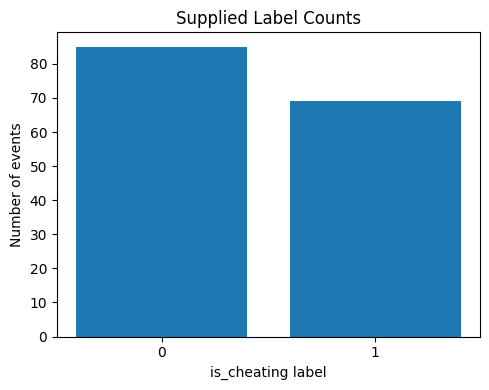

In [5]:
# 5. Inspect differences by supplied label (descriptive only)
features = ["tab_switches", "eye_gaze_angle", "audio_db"]
display(model_df.groupby("is_cheating")[features].agg(["mean", "median", "std"]).round(2))

label_counts = model_df["is_cheating"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar([str(i) for i in label_counts.index], label_counts.values)
ax.set_title("Supplied Label Counts")
ax.set_xlabel("is_cheating label")
ax.set_ylabel("Number of events")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "label_counts.png", dpi=180)
plt.show()
plt.close(fig)

## Chronological model evaluation

Rows are kept in timestamp order. The earliest 60% are used for training, the next 20% for validation, and the latest 20% for the final test. The decision threshold is chosen on validation data only. The test set is held back until final evaluation.

Because the dataset is small and appears to represent one time period/session, the scores are preliminary and may not generalize to other sessions or students.

In [6]:
# 6. Chronological train / validation / test split
from sklearn.ensemble import RandomForestClassifier

data = model_df.sort_values("timestamp").reset_index(drop=True)
features = ["tab_switches", "eye_gaze_angle", "audio_db"]
target = "is_cheating"
X = data[features]
y = data[target].astype(int)

n = len(data)
train_end = int(n * 0.60)
val_end = int(n * 0.80)
X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("Train:", len(X_train), "rows | labels:", y_train.value_counts().sort_index().to_dict())
print("Validation:", len(X_val), "rows | labels:", y_val.value_counts().sort_index().to_dict())
print("Test:", len(X_test), "rows | labels:", y_test.value_counts().sort_index().to_dict())

if y_train.nunique() < 2 or y_val.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError("At least two classes are needed in train, validation, and test partitions. Review data size/time splits.")

model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
model.fit(X_train, y_train)

class_one_index = list(model.classes_).index(1)
val_prob = model.predict_proba(X_val)[:, class_one_index]
precision_vals, recall_vals, thresholds = precision_recall_curve(y_val, val_prob)

if len(thresholds) == 0:
    best_threshold = 0.5
else:
    f1_vals = (2 * precision_vals[:-1] * recall_vals[:-1] /
               (precision_vals[:-1] + recall_vals[:-1] + 1e-12))
    best_threshold = float(thresholds[int(np.argmax(f1_vals))])

print("Validation-selected threshold:", round(best_threshold, 4))

Train: 92 rows | labels: {0: 52, 1: 40}
Validation: 31 rows | labels: {0: 20, 1: 11}
Test: 31 rows | labels: {0: 13, 1: 18}
Validation-selected threshold: 0.5415


In [7]:
# 7. Final test evaluation (run once after threshold selection)
test_prob = model.predict_proba(X_test)[:, class_one_index]
test_pred = (test_prob >= best_threshold).astype(int)

metrics = {
    "test_rows": int(len(y_test)),
    "threshold_selected_on_validation": float(best_threshold),
    "accuracy": float(accuracy_score(y_test, test_pred)),
    "precision_label_1": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall_label_1": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1_label_1": float(f1_score(y_test, test_pred, zero_division=0)),
    "confusion_matrix_labels_0_1": confusion_matrix(y_test, test_pred, labels=[0, 1]).tolist()
}
if y_test.nunique() == 2:
    metrics["roc_auc"] = float(roc_auc_score(y_test, test_prob))

print("===== FINAL TEST RESULTS =====")
print(json.dumps(metrics, indent=2))
print("\nClassification report:\n")
print(classification_report(y_test, test_pred, labels=[0, 1], target_names=["Label 0", "Label 1"], zero_division=0))

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

importance = pd.Series(model.feature_importances_, index=features).sort_values(ascending=True)
print("Feature importance (model-specific, not causal):\n", importance.sort_values(ascending=False).round(4))

===== FINAL TEST RESULTS =====
{
  "test_rows": 31,
  "threshold_selected_on_validation": 0.5415265362070459,
  "accuracy": 0.967741935483871,
  "precision_label_1": 0.9473684210526315,
  "recall_label_1": 1.0,
  "f1_label_1": 0.972972972972973,
  "confusion_matrix_labels_0_1": [
    [
      12,
      1
    ],
    [
      0,
      18
    ]
  ],
  "roc_auc": 0.9743589743589745
}

Classification report:

              precision    recall  f1-score   support

     Label 0       1.00      0.92      0.96        13
     Label 1       0.95      1.00      0.97        18

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31

Feature importance (model-specific, not causal):
 eye_gaze_angle    0.4061
audio_db          0.3829
tab_switches      0.2111
dtype: float64


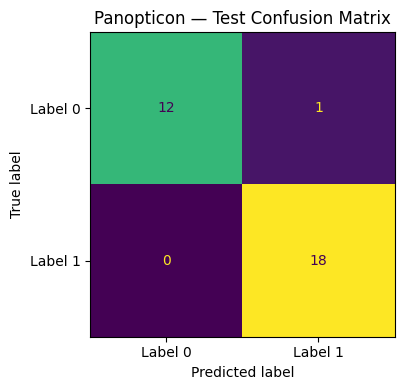

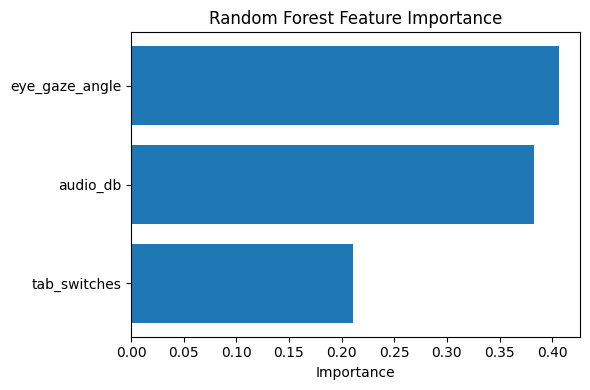

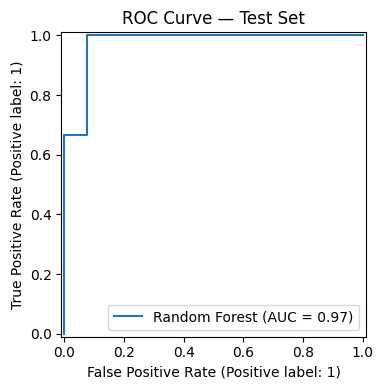

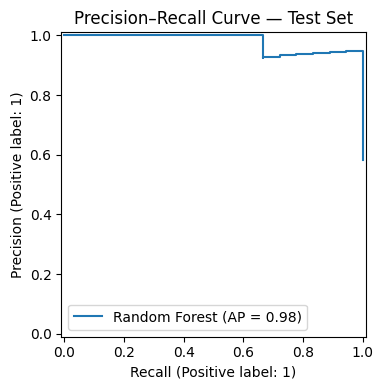

Saved files:
- outputs/confusion_matrix.png
- outputs/feature_importance.png
- outputs/label_counts.png
- outputs/metrics.json
- outputs/precision_recall_curve.png
- outputs/roc_curve.png


In [8]:
# 8. Save final evaluation plots
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=[0, 1], display_labels=["Label 0", "Label 1"],
    ax=ax, colorbar=False
)
ax.set_title("Panopticon — Test Confusion Matrix")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=180)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(importance.index, importance.values)
ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Importance")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_importance.png", dpi=180)
plt.show()
plt.close(fig)

if y_test.nunique() == 2:
    fig, ax = plt.subplots(figsize=(5, 4))
    RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax, name="Random Forest")
    ax.set_title("ROC Curve — Test Set")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "roc_curve.png", dpi=180)
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(5, 4))
    PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax, name="Random Forest")
    ax.set_title("Precision–Recall Curve — Test Set")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "precision_recall_curve.png", dpi=180)
    plt.show()
    plt.close(fig)

print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.as_posix())

## Before publishing

- Record the true source of both CSV files and the definition used to create `is_cheating`.
- Verify whether labels were generated from gaze/audio/tab-switch patterns. If they were, high scores may reflect label rules rather than generalizable behavior.
- Do not report test metrics without also reporting the small test-set size and limitations.
- Do not publish datasets unless you have permission and have checked for personal/sensitive information.
- This is an exploratory classifier, not a validated proctoring or disciplinary decision system.

### Next repository files
After this notebook runs from a fresh session, add a `README.md`, `requirements.txt`, and the saved plots under `outputs/`. The notebook currently only needs the two CSV files uploaded by the user; it does not bundle them.